# 02 — Baselines and temporal backtesting

This notebook builds the first honest forecasting benchmark for the Corporación Favorita data.

**Business target:** predict daily `sales` for every `store_nbr + family` combination over a 16-day horizon.

**Main metric:** RMSLE (lower is better). The validation window reproduces Kaggle's 16-day forecast horizon.

## Why baselines first?

A baseline is a simple rule that a later ML model must beat. We will compare:

- **Last value:** repeat the final known sale for the entire horizon.
- **Seasonal 7:** repeat the last known week twice, plus two days.
- **Seasonal 14:** repeat the last known 14-day pattern.
- **Seasonal 28:** use the sale from exactly 28 days earlier.
- **Mean 28:** repeat the mean of the final 28 known days.

All predictors use only information available on or before the forecast cutoff.

In [1]:
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(20)

print("Polars version:", pl.__version__)

Polars version: 1.44.2


In [2]:
def find_project_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "raw" / "train.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find data/raw/train.csv. Place this notebook inside the project."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_PATH = RAW_DATA_DIR / "train.csv"

print("Project root:", PROJECT_ROOT)
print("Train path:", TRAIN_PATH)

Project root: retail-demand-forecasting
Train path: retail-demand-forecasting/data/raw/train.csv


In [3]:
train = pl.read_csv(
    TRAIN_PATH,
    schema_overrides={
        "id": pl.Int64,
        "store_nbr": pl.Int64,
        "family": pl.String,
        "sales": pl.Float64,
        "onpromotion": pl.Int64,
    },
    try_parse_dates=True,
).sort(["date", "store_nbr", "family"])

print("Shape:", train.shape)
print("Date range:", train["date"].min(), "to", train["date"].max())
train.head()

Shape: (3000888, 6)
Date range: 2013-01-01 to 2017-08-15


id,date,store_nbr,family,sales,onpromotion
i64,date,i64,str,f64,i64
0,2013-01-01,1,"""AUTOMOTIVE""",0.0,0
1,2013-01-01,1,"""BABY CARE""",0.0,0
2,2013-01-01,1,"""BEAUTY""",0.0,0
3,2013-01-01,1,"""BEVERAGES""",0.0,0
4,2013-01-01,1,"""BOOKS""",0.0,0


## Temporal holdout

The final 16 days of `train.csv` become validation. Everything before them is historical training data. This simulates standing at the end of 2017-07-30 and forecasting through 2017-08-15.

In [4]:
HORIZON = 16
SERIES_KEYS = ["store_nbr", "family"]
ROW_KEYS = ["date", *SERIES_KEYS]

max_date = train["date"].max()
validation_start = max_date - timedelta(days=HORIZON - 1)
cutoff_date = validation_start - timedelta(days=1)

history = train.filter(pl.col("date") <= cutoff_date)
validation = train.filter(pl.col("date") >= validation_start)

expected_rows = HORIZON * train.select(SERIES_KEYS).unique().height

print("Forecast cutoff:", cutoff_date)
print("Validation window:", validation_start, "to", max_date)
print("History rows:", history.height)
print("Validation rows:", validation.height)
print("Expected validation rows:", expected_rows)

assert validation.height == expected_rows, "Validation grid is incomplete."
assert history["date"].max() < validation["date"].min(), "Temporal leakage detected."

Forecast cutoff: 2017-07-30
Validation window: 2017-07-31 to 2017-08-15
History rows: 2972376
Validation rows: 28512
Expected validation rows: 28512


## RMSLE and evaluation helpers

RMSLE compares `log1p(actual)` with `log1p(prediction)`. Predictions are clipped at zero because negative demand is impossible.

In [5]:
def score_predictions(predictions: pl.DataFrame, baseline_name: str):
    scored = (
        validation.select([*ROW_KEYS, "sales"])
        .join(predictions, on=ROW_KEYS, how="left")
        .with_columns(
            pl.col("prediction").fill_null(0.0).clip(0.0, float("inf")),
        )
        .with_columns(
            (pl.col("prediction").log1p() - pl.col("sales").log1p())
            .pow(2)
            .alias("squared_log_error")
        )
    )

    assert scored["prediction"].null_count() == 0
    assert scored.height == validation.height

    global_score = scored.select(
        pl.col("squared_log_error").mean().sqrt()
    ).item()

    family_scores = (
        scored.group_by("family")
        .agg(
            pl.col("squared_log_error").mean().sqrt().alias("rmsle"),
            pl.len().alias("observations"),
            pl.col("sales").sum().alias("actual_sales"),
        )
        .with_columns(pl.lit(baseline_name).alias("baseline"))
    )

    return scored, global_score, family_scores


last_known = (
    history.group_by(SERIES_KEYS)
    .agg(pl.col("sales").last().alias("fallback_prediction"))
)


def complete_predictions(partial: pl.DataFrame) -> pl.DataFrame:
    return (
        validation.select(ROW_KEYS)
        .join(partial, on=ROW_KEYS, how="left")
        .join(last_known, on=SERIES_KEYS, how="left")
        .with_columns(
            pl.coalesce(["prediction", "fallback_prediction", pl.lit(0.0)])
            .alias("prediction")
        )
        .select([*ROW_KEYS, "prediction"])
    )

## Build leakage-free baselines

The seasonal mappings below only point to dates on or before the cutoff. For example, `seasonal_7` repeats the final observed week instead of using actual values from the validation window.

In [6]:
validation_dates = sorted(validation["date"].unique().to_list())


def repeated_pattern_baseline(period: int) -> pl.DataFrame:
    pattern_start = cutoff_date - timedelta(days=period - 1)
    date_map = pl.DataFrame(
        {
            "date": validation_dates,
            "source_date": [
                pattern_start + timedelta(days=index % period)
                for index in range(HORIZON)
            ],
        },
        schema_overrides={"date": pl.Date, "source_date": pl.Date},
    )

    source_values = history.select(
        pl.col("date").alias("source_date"),
        *SERIES_KEYS,
        pl.col("sales").alias("prediction"),
    )

    partial = (
        validation.select(ROW_KEYS)
        .join(date_map, on="date", how="left")
        .join(source_values, on=["source_date", *SERIES_KEYS], how="left")
        .select([*ROW_KEYS, "prediction"])
    )
    return complete_predictions(partial)


last_value_predictions = complete_predictions(
    validation.select(ROW_KEYS)
    .join(last_known, on=SERIES_KEYS, how="left")
    .rename({"fallback_prediction": "prediction"})
)

seasonal_7_predictions = repeated_pattern_baseline(7)
seasonal_14_predictions = repeated_pattern_baseline(14)

source_28 = history.select(
    (pl.col("date") + timedelta(days=28)).alias("date"),
    *SERIES_KEYS,
    pl.col("sales").alias("prediction"),
)
seasonal_28_predictions = complete_predictions(source_28)

mean_28_by_series = (
    history.filter(pl.col("date") >= cutoff_date - timedelta(days=27))
    .group_by(SERIES_KEYS)
    .agg(pl.col("sales").mean().alias("prediction"))
)
mean_28_predictions = complete_predictions(
    validation.select(ROW_KEYS).join(mean_28_by_series, on=SERIES_KEYS, how="left")
)

print("Baselines created. Rows per baseline:", last_value_predictions.height)

Baselines created. Rows per baseline: 28512


In [7]:
baselines = {
    "last_value": last_value_predictions,
    "seasonal_7": seasonal_7_predictions,
    "seasonal_14": seasonal_14_predictions,
    "seasonal_28": seasonal_28_predictions,
    "mean_28": mean_28_predictions,
}

global_results = []
family_results = []
scored_frames = {}

for name, predictions in baselines.items():
    scored, global_rmsle, by_family = score_predictions(predictions, name)
    scored_frames[name] = scored
    global_results.append(
        {
            "baseline": name,
            "rmsle": global_rmsle,
            "observations": scored.height,
            "horizon_days": HORIZON,
        }
    )
    family_results.append(by_family)

results = pl.DataFrame(global_results).sort("rmsle")
family_scores = pl.concat(family_results)

print("Baseline leaderboard (lower RMSLE is better):")
results

Baseline leaderboard (lower RMSLE is better):


baseline,rmsle,observations,horizon_days
str,f64,i64,i64
"""mean_28""",0.521588,28512,16
"""seasonal_7""",0.61704,28512,16
"""seasonal_14""",0.625209,28512,16
"""seasonal_28""",0.627441,28512,16
"""last_value""",0.659484,28512,16


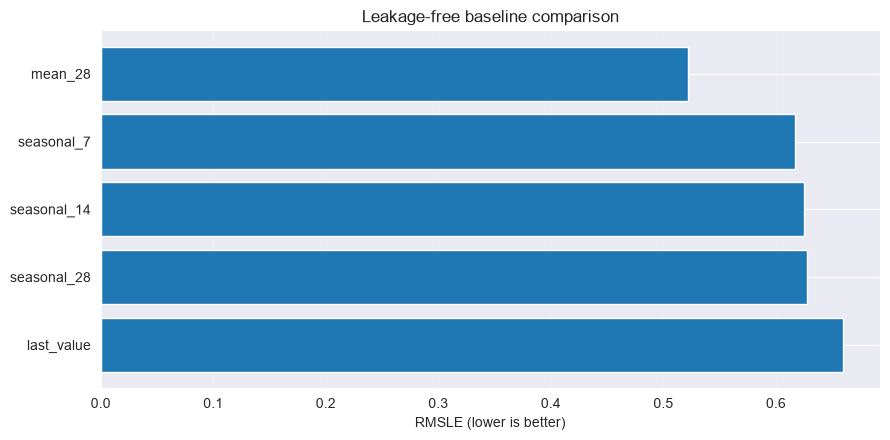

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_data = results.sort("rmsle", descending=True)
ax.barh(plot_data["baseline"].to_list(), plot_data["rmsle"].to_list())
ax.set_title("Leakage-free baseline comparison")
ax.set_xlabel("RMSLE (lower is better)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## Diagnose the winning baseline

A global metric can hide weak performance in sparse families. The next cells show the best and worst families for the winning baseline, plus performance by forecast day.

In [9]:
best_baseline = results.row(0, named=True)["baseline"]
best_family_scores = (
    family_scores.filter(pl.col("baseline") == best_baseline)
    .sort("rmsle", descending=True)
)

print("Winning baseline:", best_baseline)
print("\n10 hardest families:")
display(best_family_scores.head(10))

print("10 easiest families:")
display(best_family_scores.tail(10).sort("rmsle"))

Winning baseline: mean_28

10 hardest families:


family,rmsle,observations,actual_sales,baseline
str,f64,u32,f64,str
"""SCHOOL AND OFFICE SUPPLIES""",1.642243,864,51795.0,"""mean_28"""
"""LIQUOR,WINE,BEER""",0.693693,864,84091.0,"""mean_28"""
"""GROCERY II""",0.679503,864,25031.0,"""mean_28"""
"""LINGERIE""",0.662268,864,6716.0,"""mean_28"""
"""CELEBRATION""",0.607399,864,10768.0,"""mean_28"""
"""LADIESWEAR""",0.580189,864,8711.0,"""mean_28"""
"""HARDWARE""",0.555705,864,1252.0,"""mean_28"""
"""SEAFOOD""",0.554325,864,17260.919022,"""mean_28"""
"""BEAUTY""",0.553143,864,5757.0,"""mean_28"""


10 easiest families:


family,rmsle,observations,actual_sales,baseline
str,f64,u32,f64,str
"""BOOKS""",0.081988,864,9.0,"""mean_28"""
"""DAIRY""",0.216793,864,721034.0,"""mean_28"""
"""GROCERY I""",0.221638,864,3.9804e6,"""mean_28"""
"""BREAD/BAKERY""",0.2324,864,466795.50089,"""mean_28"""
"""DELI""",0.239552,864,261902.894004,"""mean_28"""
"""BEVERAGES""",0.276948,864,3.005407e6,"""mean_28"""
"""PRODUCE""",0.282457,864,1.9775e6,"""mean_28"""
"""PERSONAL CARE""",0.28691,864,277631.0,"""mean_28"""
"""POULTRY""",0.289741,864,323560.26891,"""mean_28"""


In [10]:
best_scored = scored_frames[best_baseline].with_columns(
    ((pl.col("date") - pl.lit(validation_start)).dt.total_days() + 1)
    .alias("forecast_day")
)

score_by_horizon = (
    best_scored.group_by("forecast_day")
    .agg(
        pl.col("squared_log_error").mean().sqrt().alias("rmsle"),
        pl.col("sales").sum().alias("actual_sales"),
        pl.col("prediction").sum().alias("predicted_sales"),
    )
    .sort("forecast_day")
)

score_by_horizon

forecast_day,rmsle,actual_sales,predicted_sales
i64,f64,f64,f64
1,0.472409,885856.84087,843632.556626
2,0.467099,988527.763204,843632.556626
3,0.474172,964712.016051,843632.556626
4,0.505434,728068.485132,843632.556626
5,0.512329,827775.686128,843632.556626
6,0.494273,965693.650492,843632.556626
7,0.543043,1.0496e6,843632.556626
8,0.524749,797464.963817,843632.556626
9,0.543587,717766.349106,843632.556626


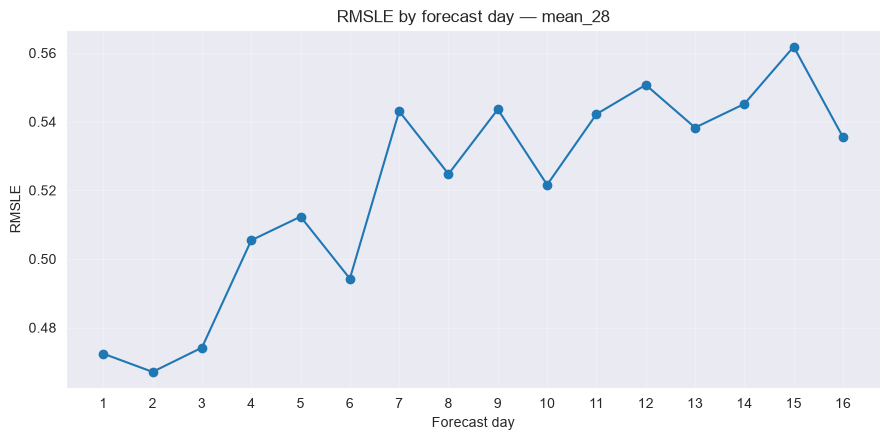

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    score_by_horizon["forecast_day"].to_list(),
    score_by_horizon["rmsle"].to_list(),
    marker="o",
)
ax.set_title(f"RMSLE by forecast day — {best_baseline}")
ax.set_xlabel("Forecast day")
ax.set_ylabel("RMSLE")
ax.set_xticks(range(1, HORIZON + 1))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## How to interpret the result

After execution, record the following in the project README:

1. Which baseline obtained the lowest global RMSLE?
2. Which families were hardest to forecast?
3. Does error increase deeper into the 16-day horizon?
4. Does the baseline systematically overpredict or underpredict total sales?

The winning score becomes the minimum target for the first ML model. LightGBM will only count as an improvement if it achieves a lower RMSLE on the same validation dates without using future information.

### Next notebook

`03_feature_engineering.ipynb`: calendar variables, known promotions, store metadata, correctly localized holidays, oil, and leakage-safe sales lags/rolling features.